<a href="https://colab.research.google.com/github/UnitForDataScience/Finding-Patterns_An-Introduction-to-Cluster-Analysis/blob/main/Colab_Notebook/Finding_Patterns_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Finding Patterns: An Introduction to Cluster Analysis
*An Open Lab by the Unit for Data Science and Analytics at ASU Library*


---
The purpose of this notebook is to help you understand how **K-means**, **DBSCAN**, and **hierarchical clustering** work through some fun exercises that give you a better sense of what goes on under the hood. These methods are *unsupervised machine learning* algorithms: we give them unlabeled data (only points, no categories or labels), and they find patterns that break the data into clusters, or groups. These particular methods are best suited for **continuous data**, meaning numeric measurements like age, income, or height. We have kept the code at a beginner-to-intermediate level (that's all you need!) and added comments throughout so you can follow along. Feel free to ask questions!

##**Before you start:**

1.   Sign In: Make sure you are signed in to your ASU or personal Google account.
2.   Make a copy: On the top-left menu bar, go to File>Save a copy in Drive

3. Work on Your Copy: A new tab will open with a file named "Copy of [Notebook Name]". You can now rename it and your changes will be saved automatically to your own Drive.
Your copy will automatically be saved in a folder in your Google Drive called "Colab Notebooks" (Google Drive creates this folder automatically for you)


##**How to use this notebook:**

*   The notebook is divided into four sections. These sections are mini-lessons and are coded to run separately form one another. Run the cells for each section from top to bottom: click a cell and press Shift + Enter. The cells in each part depend on earlier ones, so run each section in order, or use Runtime > Run all to run the whole notebook.
*   Look for the 🔧 **Your turn** boxes: change a number, re-run the cell, and see what happens.


# Part 1: Using K-means to compress a picture

A photo is a big table of pixels, and every pixel has three numbers: how much **R**ed, **G**reen and **B**lue it has. That means every pixel is a point in 3D "color space". K-means can group those points into *k* clusters. The center of each cluster becomes one representative color, so the whole photo can be redrawn using only *k* colors.

First, let's load the libraries and a sample photo.

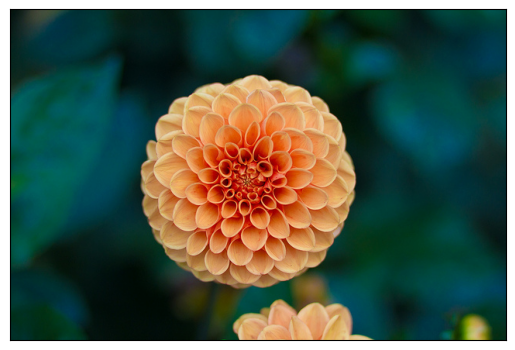

In [1]:
# Loading the necessary libraries
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.datasets import load_sample_image
from sklearn.cluster import MiniBatchKMeans

# Loading an image
flower = load_sample_image("flower.jpg")
ax = plt.axes(xticks=[], yticks=[])
ax.imshow(flower);
plt.show()

## Turn the photo into a table of points

Each row below is one pixel: `[Red, Green, Blue]`, each between 0 and 1. We also count how many *different* colors the photo uses.

In [2]:
data = flower / 255.0 # use 0...1 scale
data = data.reshape(-1, 3)

# See the shape of the transformed dataset
print("Total Pixels:", len(data))
print()

# Display the first 20 pixels with an empty line after
print("Preview of Pixel Dataset in RGB: ")
print(data[:20])
print()

# Reshape and normalize the image pixels to compute unique colors
unique_colors = np.unique(data, axis=0)

# Calculate and print the number of unique colors in the original image
original_unique_count = len(unique_colors)
print(f"The original image contains {original_unique_count:,} unique colors.")

Total Pixels: 273280

Preview of Pixel Dataset in RGB: 
[[0.00784314 0.0745098  0.05098039]
 [0.01176471 0.07058824 0.05098039]
 [0.02745098 0.07843137 0.05098039]
 [0.03137255 0.08235294 0.05490196]
 [0.02352941 0.08235294 0.05490196]
 [0.01568627 0.08235294 0.05882353]
 [0.01960784 0.08235294 0.07058824]
 [0.03137255 0.09019608 0.07843137]
 [0.02352941 0.08627451 0.08235294]
 [0.03529412 0.09411765 0.08235294]
 [0.04313725 0.10196078 0.08235294]
 [0.05490196 0.10196078 0.08627451]
 [0.0627451  0.11372549 0.08627451]
 [0.07058824 0.12156863 0.09411765]
 [0.06666667 0.1254902  0.09803922]
 [0.06666667 0.1254902  0.09803922]
 [0.07843137 0.14117647 0.10196078]
 [0.09019608 0.14117647 0.11372549]
 [0.10196078 0.14509804 0.12156863]
 [0.11372549 0.15686275 0.13333333]]

The original image contains 62,941 unique colors.


## Look at the points

Each dot below is a pixel, drawn in its own color. The left plot shows Red vs. Green, the right plot shows Red vs. Blue. (We plot a random 10,000 pixels so it draws quickly.)

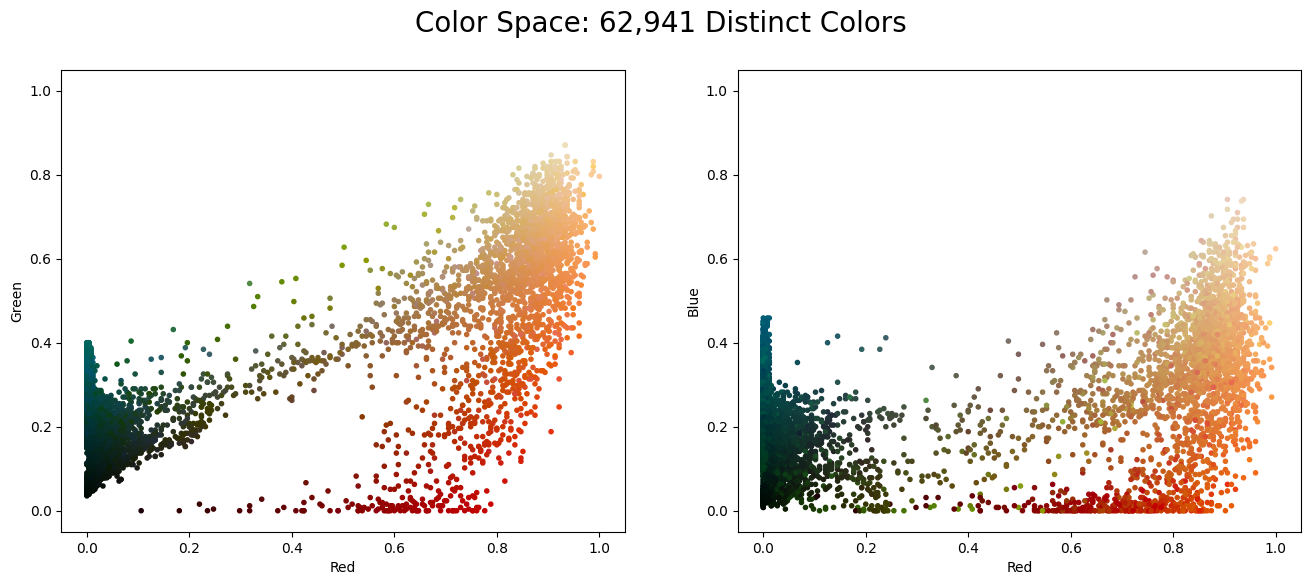

In [3]:
# Define plotting function that optionally overlays the centroids
def plot_pixels(data, title, colors=None, centroids=None, N=10000):
    if colors is None:
        colors = data

    # choose a random subset for background visualization
    rng = np.random.default_rng(0)
    i = rng.permutation(data.shape[0])[:N]
    colors_sub = colors[i]
    R, G, B = data[i].T

    fig, ax = plt.subplots(1, 2, figsize=(16, 6))

    # Red vs Green
    ax[0].scatter(R, G, color=colors_sub, marker='.', alpha=0.3 if centroids is not None else 1.0)
    if centroids is not None:
        ax[0].scatter(centroids[:, 0], centroids[:, 1], color=centroids, marker='*', s=250, edgecolor='white', linewidths=1.5)
    ax[0].set(xlabel='Red', ylabel='Green', xlim=(-0.05, 1.05), ylim=(-0.05, 1.05))

    # Red vs Blue
    ax[1].scatter(R, B, color=colors_sub, marker='.', alpha=0.3 if centroids is not None else 1.0)
    if centroids is not None:
        ax[1].scatter(centroids[:, 0], centroids[:, 2], color=centroids, marker='*', s=250, edgecolor='white', linewidths=1.5)
    ax[1].set(xlabel='Red', ylabel='Blue', xlim=(-0.05, 1.05), ylim=(-0.05, 1.05))

    fig.suptitle(title, size=20)

# Plot the input color space
plot_pixels(data, title=f'Color Space: {original_unique_count:,} Distinct Colors')

## Clustering with K-means

We ask K-means for `reduced_colors` clusters. Each cluster center is a color, and together the centers form the photo's new **palette**.

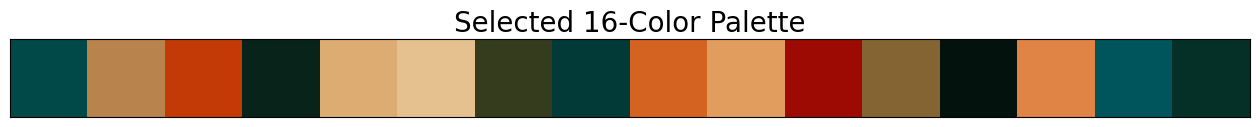

In [4]:
# Choose number of colors to reduce to
reduced_colors=16

# Perform K-Means to reduce colors
kmeans = MiniBatchKMeans(reduced_colors, random_state=0)
kmeans.fit(data)
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]
centroids = kmeans.cluster_centers_

# Display the reduced color palette
fig, ax = plt.subplots(1, 1, figsize=(16, 1.5), subplot_kw=dict(xticks=[], yticks=[]))
ax.imshow([centroids])
ax.set_title(f"Selected {reduced_colors:,}-Color Palette", size=20)
plt.show()

## Visualizing the Clusters

We can call a function to visualize the points that make up the flower picture, where now each point will be repainted with the color of its cluster center. The graphs on the top show you the reduced color space, while the ones below are the same graphs but with the **centroid** of each cluster marked by a star (★).

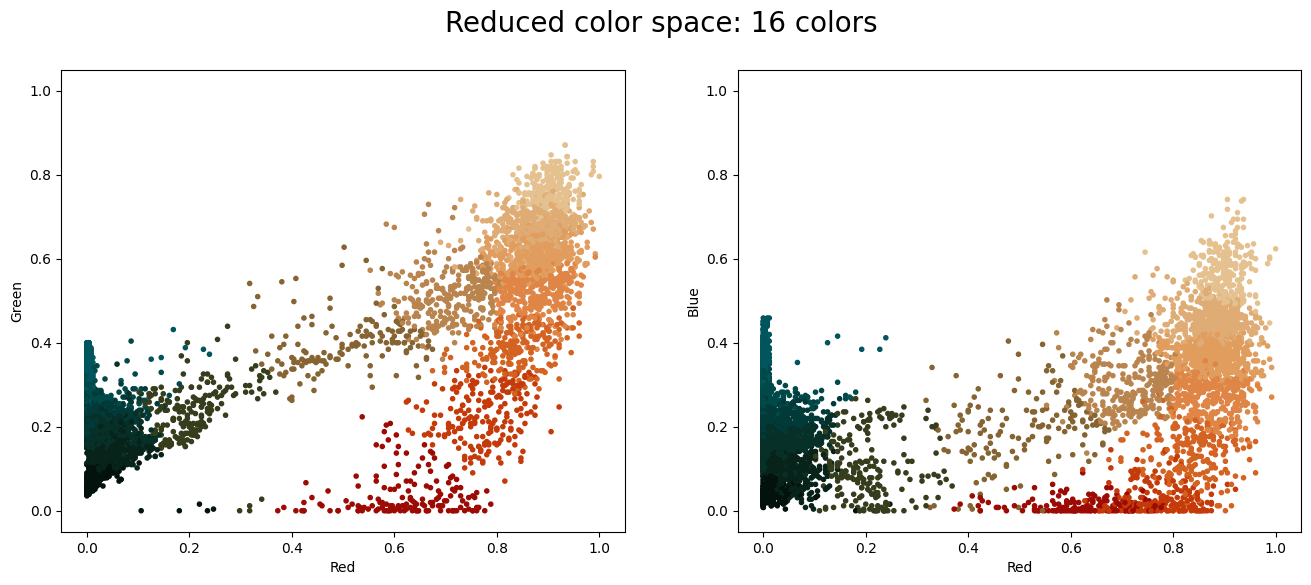

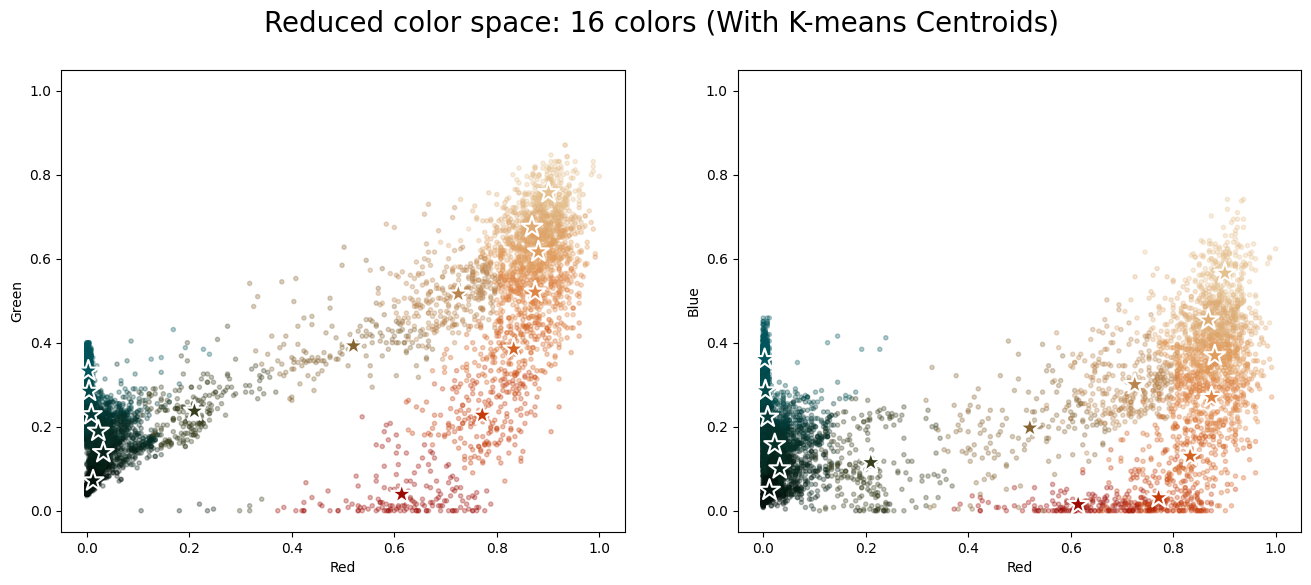

In [5]:
# 1. Visualize the reduced color space
plot_pixels(data, colors=new_colors, title=f"Reduced color space: {reduced_colors:,} colors")

# 2. Visualize the reduced color space with the overlaid k-means centroid
plot_pixels(data, colors=new_colors, title=f"Reduced color space: {reduced_colors:,} colors (With K-means Centroids)", centroids=centroids)

##The compressed image
Now that we have our clusters, we can map back all of the coordinates of our image using only the colors identified by K-means as the centroids of our clusters. The result can be seen below; compare the original picture on the left to the clustered colors on the right. Can you still tell it is a flower? What is lost in the clustering? What is gained?

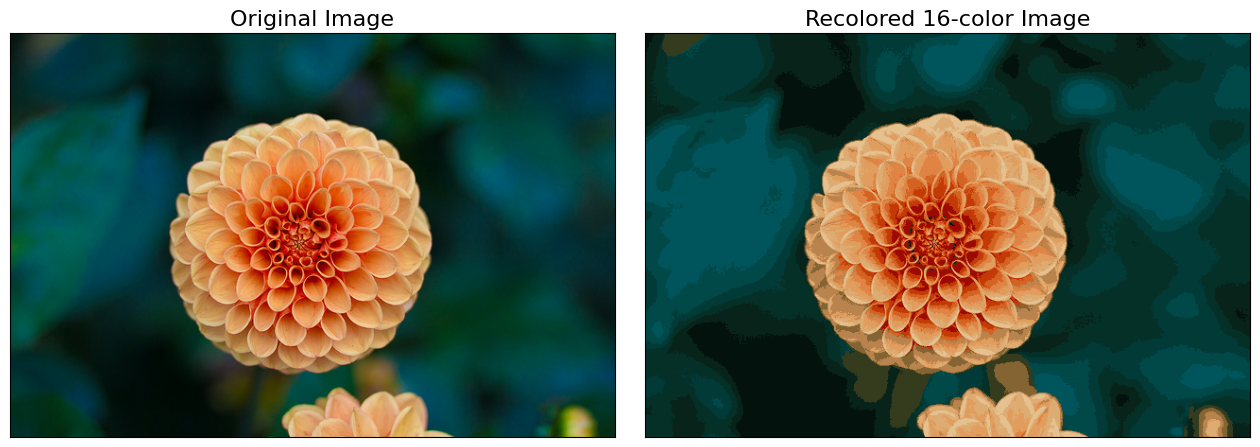

In [6]:
# Show the original vs quantized image comparison in its own cell
flower_recolored = new_colors.reshape(flower.shape)

# Display the side-by-side images
fig, ax = plt.subplots(1, 2, figsize=(16, 6), subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)
ax[0].imshow(flower)
ax[0].set_title('Original Image', size=16)
ax[1].imshow(flower_recolored)
ax[1].set_title(f'Recolored {reduced_colors:,}-color Image', size=16)
plt.show()

## 🔧 Your turn: how many colors do we really need?

1. Go back to the cell with the variable `reduced_colors`. Change the value to **8**, then **32**, then **64**. Re-run that cell and the two cells below it. At what point does the photo stop looking "wrong" to you?
2. Or run the cell below, which tries several values of *k* at once.

Here your eyes are the evaluation metric. With other data, we would use the elbow method or the silhouette score to help us find a meaningful number of clusters.

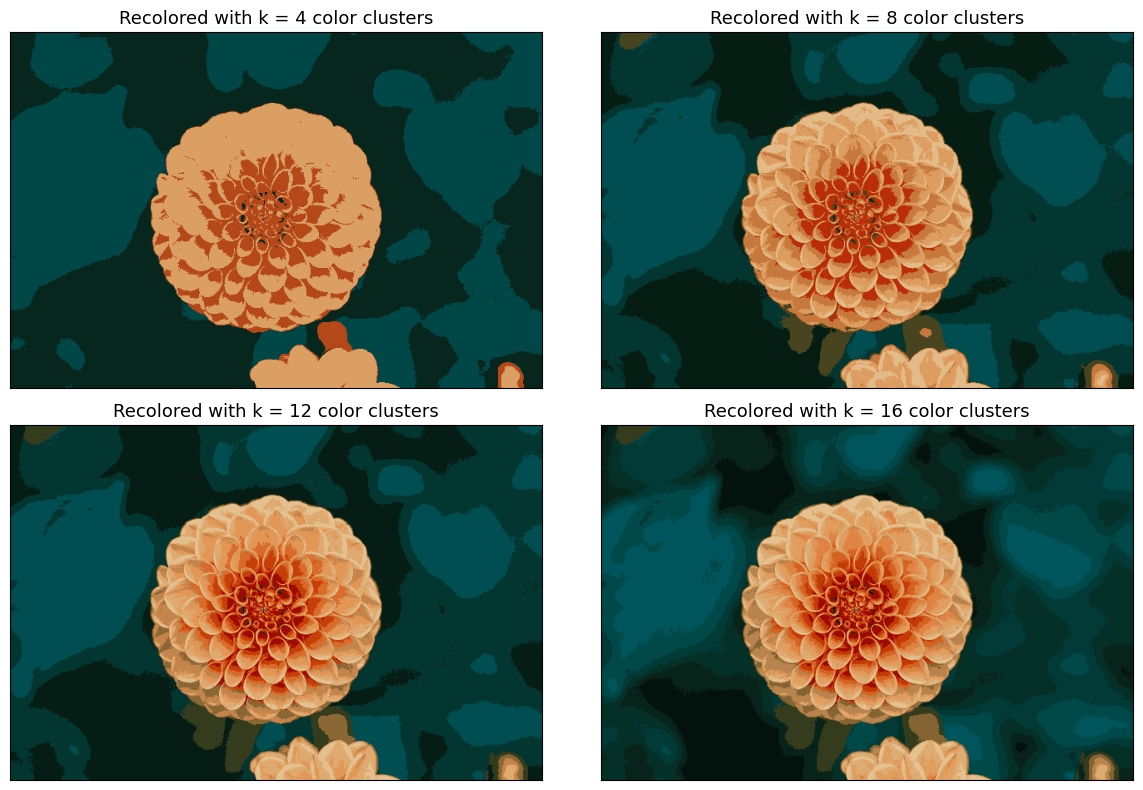

In [7]:
# Try several values of k side by side
ks = [4, 8, 12, 16] # 🔧 Feel free to change these numbers to explore how the compression looks with different values

# Plot the different images
fig, axes = plt.subplots(2, 2, figsize=(12, 8), subplot_kw=dict(xticks=[], yticks=[]))
for ax, k in zip(axes.ravel(), ks):
    km = MiniBatchKMeans(k, random_state=0).fit(data)
    recolored = km.cluster_centers_[km.predict(data)].reshape(flower.shape)
    ax.imshow(recolored)
    ax.set_title(f"Recolored with k = {k} color clusters", size=13)
plt.tight_layout()
plt.show()

## 🔧 **Your turn: Take-home:**

Replace `"flower.jpg"` in the very first code cell at the top of this section with `"china.jpg"` (the other photo that ships with scikit-learn) and re-run Part 1. Feel free to experiment with different numbers of "k" clusters.

# Part 2: DBSCAN vs K-means

DBSCAN finds clusters as dense regions separated by empty space, and anything left over is labeled as *noise*. We can control some hyperparameters to help us find clusters of any shape, even the shape of a letter! This example is meant to help you see the practical differences between DBSCAN and K-means clustering.


*Run the cell below first. It loads the libraries for this part, so you can run this part on its own.*

In [8]:
# Loading the necessary libraries
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.cluster import DBSCAN, KMeans

## Creating a dataset
Below we will turn a word into clusters of points, then scatter some random "static" on top; this will be our dataset for this section. Algorithms are presented with a table of coordinates for each of the points that forms the words.

Once our data points are ready, we will try to use K-means and DBSCAN to see how well each algorithm can identify each letter as a whole cluster.

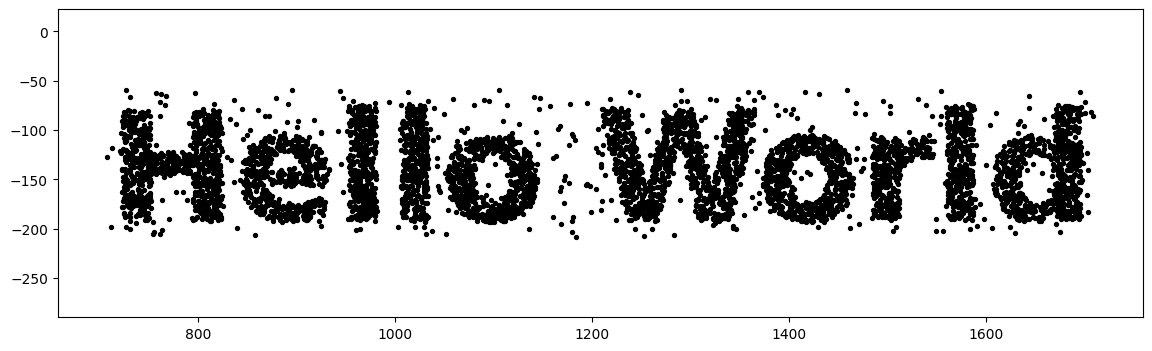

5940 points. How many groups do you see?


In [9]:
# Defining a function that will turn text into points on a plane with x and y coordinates
def text_to_points(text, n_points=None, n_noise=None, seed=0):
    """Turn a word into a cloud of (x, y) dots, plus some random noise dots."""
    n_points = n_points or 500 * len(text)
    n_noise = n_noise or 40 * len(text)

    rng = np.random.default_rng(seed)
    fig = plt.figure(figsize=(2.2*len(text), 3), dpi=100)
    fig.text(0.5, 0.5, text, fontsize=110, fontweight='bold', ha='center', va='center')
    fig.canvas.draw()
    img = np.asarray(fig.canvas.buffer_rgba())[:, :, 0]   # dark pixels = the letters
    plt.close(fig)
    ys, xs = np.where(img < 128)
    idx = rng.choice(len(xs), size=min(n_points, len(xs)), replace=False)
    pts = np.c_[xs[idx], -ys[idx]].astype(float) + rng.normal(0, 1.0, (len(idx), 2))
    lo, hi = pts.min(axis=0), pts.max(axis=0)
    noise = rng.uniform(lo - 15, hi + 15, (n_noise, 2))
    return np.vstack([pts, noise])

# Choose the word we will try to cluster, then run our function
TEXT = "Hello World"           # <-- 🔧 try other words later
points = text_to_points(TEXT)

# Plot the points
plt.figure(figsize=(14, 4))
plt.scatter(points[:, 0], points[:, 1], s=8, color='black')
plt.axis('equal')
plt.show()
print(f"{len(points)} points. How many groups do you see?")

## What does the data actually look like?

The plot is only a picture. Underneath, every dot is just **a row with two numbers**: an **x** and a **y** coordinate. Let's look at the table DBSCAN actually receives.

- **x** is how many pixels the dot is from the left edge of the image.
- **y** is the (negative) number of pixels from the top. We flip the sign so the word isn't upside down.
- **kind** tells us whether the dot is on a letter (`word`) or is random static (`noise`). The algorithm never sees this column. It only gets x and y.

In [10]:
n_noise = 40 * len(TEXT)          # same rule text_to_points uses for the random noise dots
df_points = pd.DataFrame(points, columns=["x", "y"]).round(1)
df_points["kind"] = ["word"] * (len(points) - n_noise) + ["noise"] * n_noise

print(f"{len(df_points):,} points: {(df_points['kind'] == 'word').sum():,} on the letters and {n_noise} random noise dots")
df_points.head(10)

5,940 points: 5,500 on the letters and 440 random noise dots


,x,y,kind
0,1336.3,-186.5,word
1,1416.8,-190.9,word
2,1080.6,-129.7,word
3,909.7,-141.1,word
4,1568.3,-147.1,word
5,1099.0,-114.8,word
6,1349.2,-103.1,word
7,1296.6,-135.7,word
8,1567.3,-106.4,word
9,769.0,-132.3,word


## Round 1: K-means

K-means needs to be told the *k* number of clusters we want to find, so as a first step we will use a function to count how many letters are in our phrase not counting spaces (for "Hello World" it will be 10). Run the cell below and think about how K-means actually does clustering; does it separate the letters well?

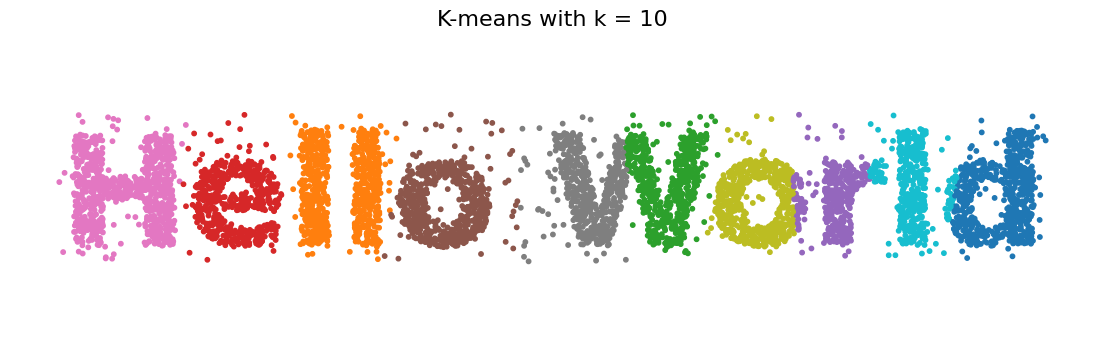

In [11]:
k = len(TEXT.replace(" ", ""))        # one group per letter (not counting spaces)
km_labels = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(points)

# Plot the chosen word or phrase showing the clusters as different colors
plt.figure(figsize=(14, 4))
plt.scatter(points[:, 0], points[:, 1], c=km_labels, cmap='tab10', s=10)
plt.title(f"K-means with k = {k}", size=16)
plt.axis('equal'); plt.axis('off')
plt.show()

## Round 2: DBSCAN
Let's try to solve the same problem with DBSCAN.

DBSCAN has two settings or hyperparameters: `eps` (Epsilon, how close counts as a neighbor) and `min_samples` (how many neighbors make a crowd, or how many points (including itself) must fall within eps). Gray **X** marks are noise: points that belong to no crowd.

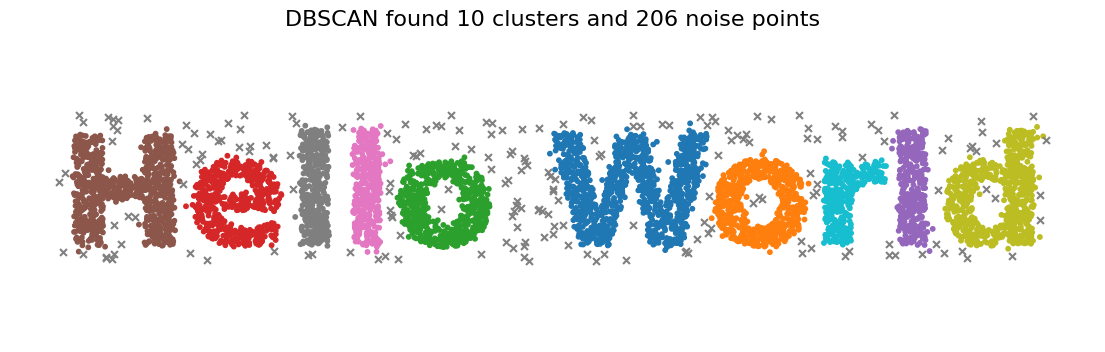

In [12]:
# Set the parameters for DBSCAN and run
db = DBSCAN(eps=8, min_samples=5).fit(points) #🔧 You can explore other values of "eps" and min_samples
labels = db.labels_
n_found = len(set(labels)) - (1 if -1 in labels else 0)

# Plot the chosen word or phrase showing the clusters as different colors
plt.figure(figsize=(14, 4))
is_noise = labels == -1
plt.scatter(points[~is_noise, 0], points[~is_noise, 1], c=labels[~is_noise], cmap='tab10', s=10)
plt.scatter(points[is_noise, 0], points[is_noise, 1], marker='x', color='gray', s=25)
plt.title(f"DBSCAN found {n_found} clusters and {is_noise.sum()} noise points", size=16)
plt.axis('equal'); plt.axis('off')
plt.show()

## 🔧  Your turn: tune DBSCAN

DBSCAN is powerful but sensitive to its settings. Run the cell below to see three different values of `eps` side by side.

1. What happens when `eps` is too **small**? Too **large**?
2. Which value finds the letters? Edit the cell below and try other values such as 6, 10, or 12. Small changes can matter a lot!
3. Change the `TEXT` variable in the first cell of this part, re-run that cell and the ones after it, and compare K-means with DBSCAN. Is there a word where K-means does well? Why do you think that happens?

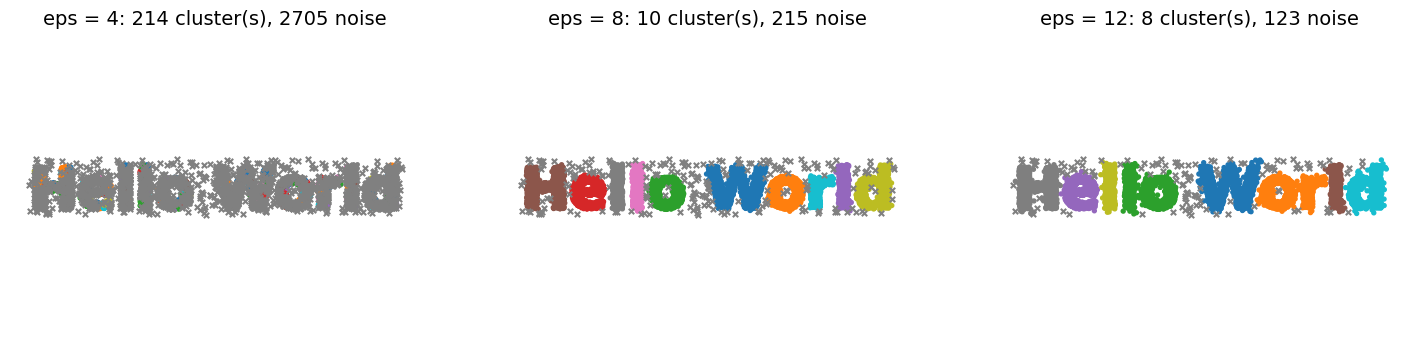

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, eps in zip(axes, [4, 8, 12]):
    labels = DBSCAN(eps=eps, min_samples=8).fit_predict(points)
    noise = labels == -1
    n = len(set(labels)) - (1 if -1 in labels else 0)
    ax.scatter(points[~noise, 0], points[~noise, 1], c=labels[~noise], cmap='tab10', s=8)
    ax.scatter(points[noise, 0], points[noise, 1], marker='x', color='gray', s=15)
    ax.set_title(f"eps = {eps}: {n} cluster(s), {noise.sum()} noise", size=14)
    ax.axis('equal'); ax.axis('off')
plt.show()

## Part 2 Bonus (Take-home)
## How do we choose `eps` in real data?

In practice, nobody tries values by hand forever. A common trick is the **k-distance plot**. For every point, we measure the distance to its `min_samples`-th closest point, then sort those distances from smallest to largest. Points inside crowds have small distances, and lonely points (noise) have large ones, so the curve stays low and then bends sharply upward. The height of the bend is a good starting value for `eps`.

Run the cell below. Is the bend close to the `eps` we used?

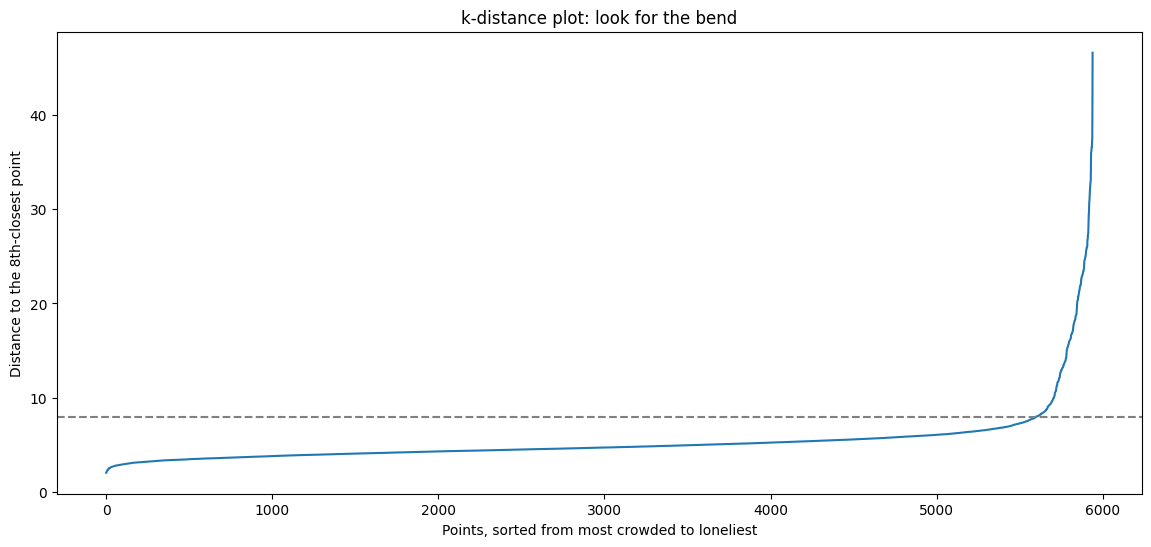

In [14]:
from sklearn.neighbors import NearestNeighbors

min_samples = 8      # use the same value as in the DBSCAN cell

# Distance from every point to its 8th-closest point (the point itself counts as the first, as in DBSCAN)
distances, _ = NearestNeighbors(n_neighbors=min_samples).fit(points).kneighbors(points)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(14, 6))
plt.plot(k_distances)
plt.axhline(8, color="gray", linestyle="--")    # compare with the eps we used (change if yours differs)
plt.xlabel("Points, sorted from most crowded to loneliest")
plt.ylabel(f"Distance to the {min_samples}th-closest point")
plt.title("k-distance plot: look for the bend")
plt.show()

# Part 3.A: Hierarchical Clustering with Real-World Data
## GDP vs Life Expectancy

In this section we will use hierarchical clustering to tackle a real-world problem. The Gapminder dataset is a famous dataset that is included with many statistical and machine learning packages, and contains data on the Gross Domestic Product (GDP) per capita for 142 countries across 12 time periods spanning half a century. The dataset famously helps show the relationship between the GDP of a country and its peoples' life expectancy.

Here, hierarchical clustering can help us group countries based on actual mathematical similarities across our chosen indicators (in this case, GDP per capita and life expectancy). This can help reveal hidden global patterns and challenge our assumptions about how the world is divided. We might see how shared historical trajectories influence countries across the world, among other implications.


*Run the cell below first. It loads the libraries for this part, so you can run this part on its own.*

In [15]:
# Loading the necessary libraries
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import pandas as pd
import plotly.express as px
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

## A short exploration
Before we cluster anything, let's look at the data. The plot below uses data from the [Gapminder](https://www.gapminder.org/) project to show the relationship between GDP per capita and life expectancy across countries. We will plot GDP per capita on the x-axis, and life expectancy on the y-axis on a bubble chart across time. The bubble size equals the size of the population of the country, and the color points to the continent.

Run the cell, then press the **Play** button to see how wealth and life expectancy changed across the world from 1952 to 2007, and hover over a bubble to see more information on each country.

In [16]:
# Sample data: Gapminder dataset (available in Plotly)
df = px.data.gapminder()


# Create an interactive scatter plot
fig = px.scatter(df,
                 x="gdpPercap",
                 y="lifeExp",
                 animation_frame="year",         # This will allow us to animate by year
                 animation_group="country",      # This plots each country separately
                 size="pop",
                 color="continent",
                 hover_name="country",
                 log_x=True,
                 size_max=70,
                 range_x=[200,60000],             # We can also specify the size of our axes
                 range_y=[25,90])

# Customize and show the plot
fig.update_layout(title='Interactive Plot: GDP vs Life Expectancy')
fig.show()

**Explore the data before moving on:**

1. Do you see **groups** of countries? How many?
2. Do the groups line up with the **colors** (continents)? Which countries break the pattern?
3. How do the groups change between 1952 and 2007?

Hierarchical clustering starts with every country on its own, then repeatedly merges the two closest groups. The result can be visualized as a **dendrogram**; countries that merge near the bottom are close relatives, and groups that only join near the top are very different.

## Setting up the dataset
After our short exploration, for the rest of this section we use a smaller set of 44 countries to keep the dendrogram readable. We're only doing this for convenience. The hierarchical clustering algorithm can take on much more data. After specifying the subset, we will show the final table produced. As a side note, you will later notice that we never tell the algorithm about continents or any other variables. It only sees two numbers per country: life expectancy and GDP per person.

In [17]:

gap = df.copy()          # life expectancy, GDP per person and population, every 5 years since 1952

countries = ['United States', 'Canada', 'Brazil', 'Argentina', 'Chile', 'Mexico', 'Peru', 'Cuba', 'Haiti',
             'Colombia', 'United Kingdom', 'France', 'Germany', 'Spain', 'Italy', 'Sweden', 'Norway',
             'Japan', 'China', 'India', 'Indonesia', 'Pakistan', 'Bangladesh', 'Thailand', 'Vietnam',
             'Philippines', 'Korea, Rep.', 'Iran', 'Turkey', 'Saudi Arabia', 'Egypt', 'Nigeria',
             'Ethiopia', 'Kenya', 'Ghana', 'Rwanda', 'Botswana', 'South Africa', 'Zimbabwe',
             'Afghanistan', 'Sierra Leone', 'Australia', 'New Zealand', 'Singapore']

missing = [c for c in countries if c not in set(gap["country"])]
if missing:
    print("Not found in the dataset, skipping:", missing)
gap = gap[gap["country"].isin(countries)].copy()

# GDP per person is very skewed (a few countries are far richer than the rest),
# so we use its logarithm: each step up means "10 times richer".
gap["log_gdp"] = np.log10(gap["gdpPercap"])

print(f"{gap['country'].nunique()} countries, {gap['year'].nunique()} years")
gap[gap["year"] == 2007].head()

44 countries, 12 years


,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num,log_gdp
11,Afghanistan,Asia,2007,43.828,31889923,974.580338,AFG,4,2.988818
59,Argentina,Americas,2007,75.320,40301927,12779.379640,ARG,32,4.106510
71,Australia,Oceania,2007,81.235,20434176,34435.367440,AUS,36,4.537005
107,Bangladesh,Asia,2007,64.062,150448339,1391.253792,BGD,50,3.143406
167,Botswana,Africa,2007,50.728,1639131,12569.851770,BWA,72,4.099330


## Hierarchical clustering and Data Preparation

In the cell below, we will prepare the data and set up our hierarchical clustering algorithm. Hierarchical clustering starts by treating every data point as its own group, then repeatedly merges the two closest groups. The result can be presented as a **dendrogram** (think of it as a tree): countries that merge near the bottom are closely related, and countries that only join near the top are very different.

### **Linkage: how do we measure the distance between *groups*?**

Hierarchical clustering keeps merging "the two closest groups," but once a group has more than one member, what does "closest" mean? Is it the distance between their nearest members? Their farthest? Their centers? That choice is called the **linkage method**, and it changes the shape of the tree.

| Linkage | The distance between two groups is... | Tends to produce |
|---|---|---|
| `"single"` | the distance between their **closest** two members | Long, stringy clusters that can follow odd shapes, but can also "chain" distant points together through a trail of neighbors |
| `"complete"` | the distance between their **farthest** two members | Compact clusters of similar size |
| `"average"` | the **average** distance across all pairs of members | Something in between single and complete |
| `"ward"` | how much the total spread **inside** the groups would grow if we merged them (we pick the merge that grows it the least) | Compact, balanced clusters, similar to K-means |

**Which one should we use?** For numeric data like ours, **Ward** is the usual starting point, which is why we use it here. If the results look odd, try the others and see what changes. Ward only works with straight-line (Euclidean) distance, but the other three also work with other distance measures.

###**Log Transform and Standardizing data**
Sometimes datasets can be less than ideal. In our case, we have values that vary in magnitude, which might obscure our analysis. The following steps will help us get better results:


1. **Log of GDP.** A few countries are far richer than the rest, which would stretch the distances and make our analysis less meaningful or hard to interpret. Transforming the GDP with its log value will help us obtaine better results.
2. **Standardize.** Life expectancy is measured in years (about 30 to 85) and GDP in thousands of dollars. Without standardizing, the bigger numbers would dominate the distance. `StandardScaler` puts both features on the same footing.

In [18]:
# Specifying the variables we will be working with
features = ["lifeExp", "log_gdp"]

# Standardize: put both features on the same scale (mean 0, spread 1) so neither one dominates the distance.
# We fit the scaler on ALL years at once, so that "distance" means the same thing in every decade.
scaler = StandardScaler().fit(gap[features])

def cluster_year(year, k=4):
    """Hierarchical clustering (Ward linkage) of the countries in one year, cut into k families."""
    d = gap[gap["year"] == year].reset_index(drop=True)
    X = scaler.transform(d[features])
    Z = linkage(X, method="ward")
    fam = fcluster(Z, k, criterion="maxclust")

    # Cluster numbers are arbitrary, so rename them 0..k-1 from lowest to highest average life expectancy
    order = d.groupby(fam)["lifeExp"].mean().sort_values().index
    rank = {f: i for i, f in enumerate(order)}
    d["cluster"] = [rank[f] for f in fam]
    return d, Z

## Read the dendrogram

The dashed line is where we "cut" the tree. Everything that is still connected below the line forms one **cluster**. A tall jump in the tree is a hint for a good place to cut.

Look for neighbors you recognize. Which countries are close relatives? Which ones surprise you?

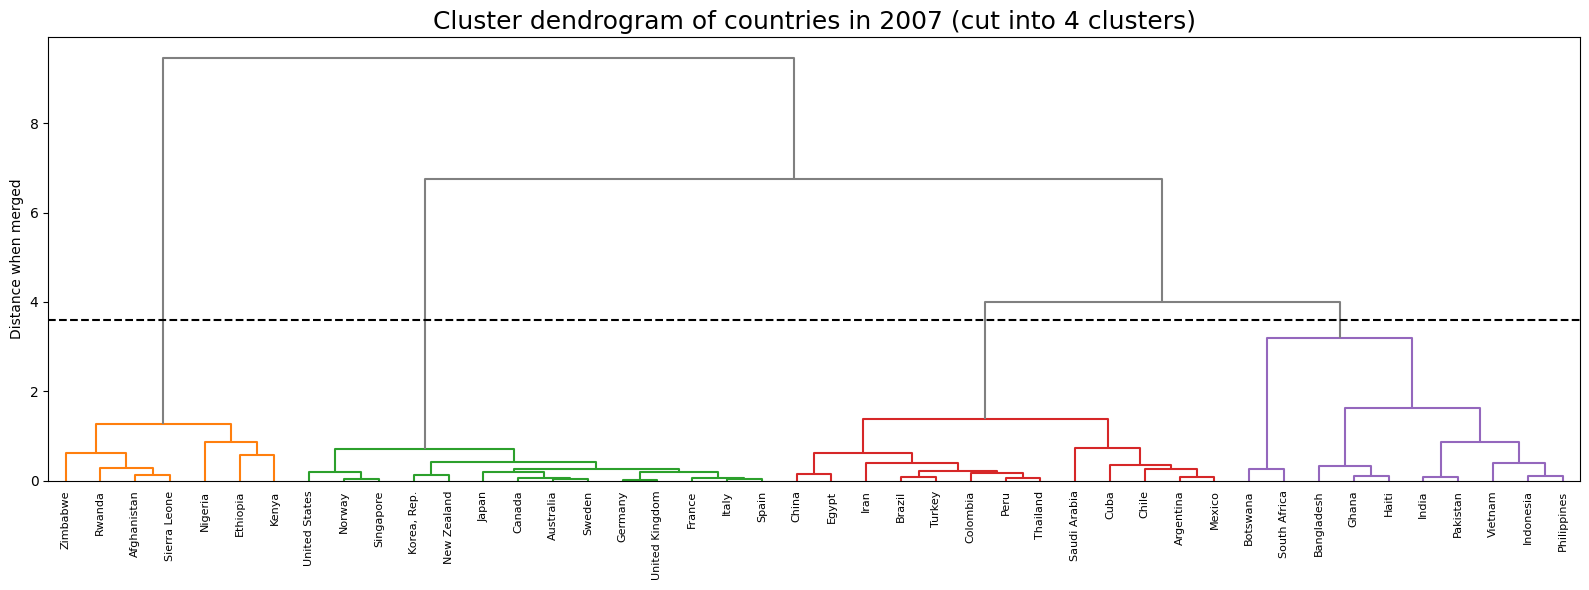

In [19]:
year = 2007      # <-- try another year: 1952, 1957, ... 2007
k = 4            # <-- try 3 or 6 families
d, Z = cluster_year(year, k)

fig, ax = plt.subplots(figsize=(16, 6))
threshold = (Z[-(k - 1), 2] + Z[-k, 2]) / 2        # a cut line between the last k-1 merges and the rest
dendrogram(Z, labels=d["country"].values, leaf_rotation=90, color_threshold=threshold,
           above_threshold_color="gray", ax=ax)
ax.axhline(threshold, color="black", linestyle="--")
ax.set_title(f"Cluster dendrogram of countries in {year} (cut into {k} clusters)", size=18)
ax.set_ylabel("Distance when merged")
plt.tight_layout()
plt.show()

## Plotting the clusters

We can now plot our chosen countries back into our original visualization. Just like before, each bubble represents a country and the bubble size is proportional to its population. GDP per person is on the horizontal axis, while life expectancy is on the vertical axis. This time around, we will code the color of each bubble to represent the cluster it belongs to.

Take a look at the final clustering, what did hierarchical clustering help us find?

In [20]:
# Helper function: given the number of clusters (k), it creates a legend label and a color for each one.
# Cluster 0 is always the lowest life expectancy and the last family is the highest, so colors keep the same meaning.
def family_style(k):
    """Legend labels and colors for k families (dark to light = low to high life expectancy)."""
    labels = [f"Cluster {i}" for i in range(k)]
    palette = [mcolors.to_hex(c) for c in plt.cm.viridis(np.linspace(0, 0.9, k))]
    return labels, dict(zip(labels, palette))

# Run the clustering for the chosen year, then add a readable "Cluster" label to each country
d, _ = cluster_year(year, k)
labels, color_map = family_style(k)
d["Cluster"] = d["cluster"].map(dict(enumerate(labels)))

fig = px.scatter(d,
                 x="gdpPercap",
                 y="lifeExp",
                 color="Cluster",
                 size="pop",
                 text="country",
                 hover_name="country",
                 hover_data={"continent": True, "Cluster": False,
                             "gdpPercap": ":,.0f", "lifeExp": ":.1f", "pop": ":,"},
                 color_discrete_map=color_map,
                 category_orders={"Cluster": labels},
                 log_x=True,
                 size_max=45,
                 range_x=[200, 60000],
                 range_y=[25, 90])

fig.update_traces(textposition="top center", textfont_size=10)
fig.update_layout(title=f"The {k} clusters in {year}", height=650)
fig.show()

## 🔧 Your turn: change the cut

1. In the tree cell, change `k = 4` to **3**, then **6**, and re-run it and the scatter plot below it. Where does the tree stop making sense to you?
2. Change `year = 2007` to **1952** and re-run both cells. Are the same countries neighbors as they were in 2007?
3. **Bonus:** add population as a third feature. Run `gap["log_pop"] = np.log10(gap["pop"])`, then change `features = ["lifeExp", "log_gdp"]` to `features = ["lifeExp", "log_gdp", "log_pop"]`, and re-run from the top of the section. What happens to China and India?

## How do the clusters change over time?

Let's run this again for every time period in the Gapminder dataset. Notice the clusters are **re-computed every time**, and the axes stay fixed, so you can watch the countries move across GDP and life expectancy, and how this changes their belonging to a cluster or another.

In [21]:

k_anim = 4          # <-- try 3 or 6 clusters

# Cluster the countries separately for every year and stack the results into one table
anim = pd.concat([cluster_year(yr, k_anim)[0] for yr in sorted(gap["year"].unique())], ignore_index=True)

# Friendly legend labels and one color per family (dark to light = low to high life expectancy)
labels, color_map = family_style(k_anim)
anim["Cluster"] = anim["cluster"].map(dict(enumerate(labels)))

fig = px.scatter(anim,
                 x="gdpPercap",
                 y="lifeExp",
                 animation_frame="year",
                 animation_group="country",
                 color="Cluster",
                 size="pop",
                 hover_name="country",
                 hover_data={"continent": True, "Cluster": False,
                             "gdpPercap": ":,.0f", "lifeExp": ":.1f", "pop": ":,"},
                 color_discrete_map=color_map,
                 category_orders={"Cluster": labels},
                 log_x=True,
                 size_max=45,
                 range_x=[200, 60000],
                 range_y=[25, 90])

fig.update_layout(title="Country clusters by era")
fig.show()

# Part 3.B (Take-home): A Conceptual Understanding of Hierarchical Clustering
## Building a family tree of colors

To get a better understanding of how hierarchical clustering works, we will use a set of named colors and cluster them into color families. Just like in Part 1, we can use RGB coordinates to find groups of similar colors, but now we cluster *named colors* instead of pixels.

*Run this cell first. It loads the libraries for this part, so you can run this part on its own.*

In [22]:
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

##Set up a color palette

Since we are learning conceptually here, let's build our own dataset by choosing a number of colors and then finding the RGB coodinates for each.

In [23]:
# Setting up a mix of named colors
# 🔧 Feel free to add some of your own, you can find a list of available colors at https://matplotlib.org/stable/gallery/color/named_colors.html
color_names = ['red', 'crimson', 'firebrick', 'darkred', 'orange', 'darkorange', 'gold', 'yellow',
               'khaki', 'olive', 'yellowgreen', 'limegreen', 'green', 'darkgreen', 'seagreen',
               'teal', 'turquoise', 'cyan', 'skyblue', 'dodgerblue', 'blue', 'navy', 'royalblue',
               'indigo', 'purple', 'orchid', 'magenta', 'hotpink', 'pink', 'brown', 'sienna',
               'tan', 'beige', 'gray', 'silver', 'black', 'white']
color_rgb = {name: mcolors.to_rgb(name) for name in color_names}


names = list(color_rgb.keys())
rgb = np.array([color_rgb[n] for n in names])
print(f"We will cluster {len(names)} colors, each described by 3 numbers (R, G, B).")

We will cluster 37 colors, each described by 3 numbers (R, G, B).


##Creating color clusters
Hierarchical clustering starts by treating every color as its own group, then repeatedly merges the two closest groups. The result is a **dendrogram**; colors that merge near the bottom are closely related (think in terms of their RGB values), and colors that only join near the top are very different.

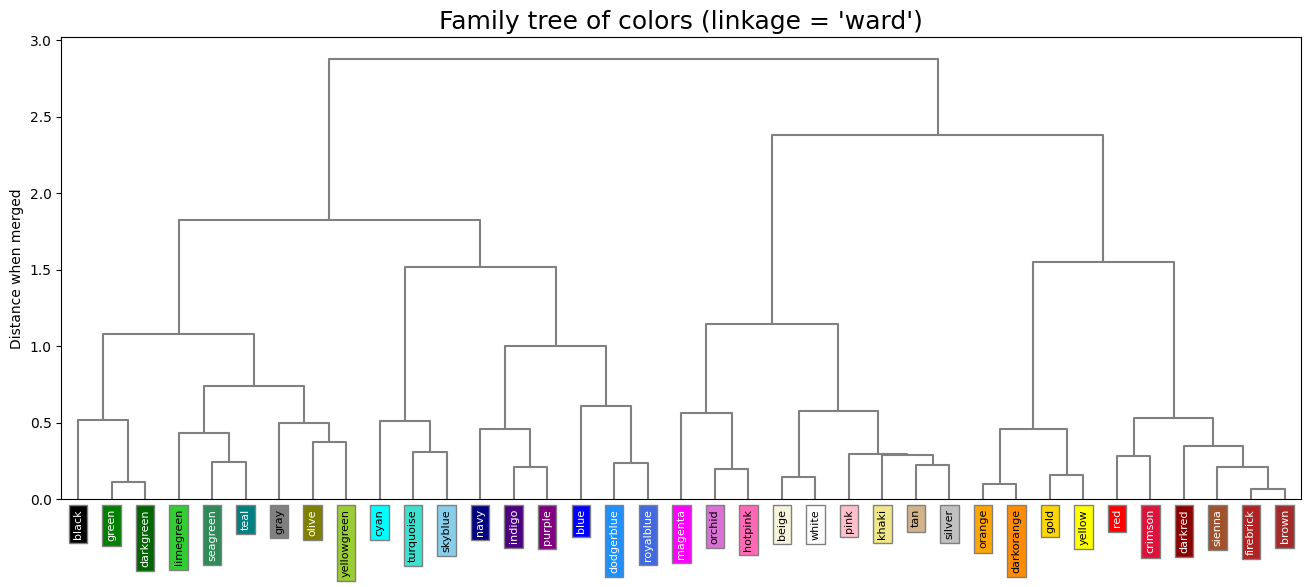

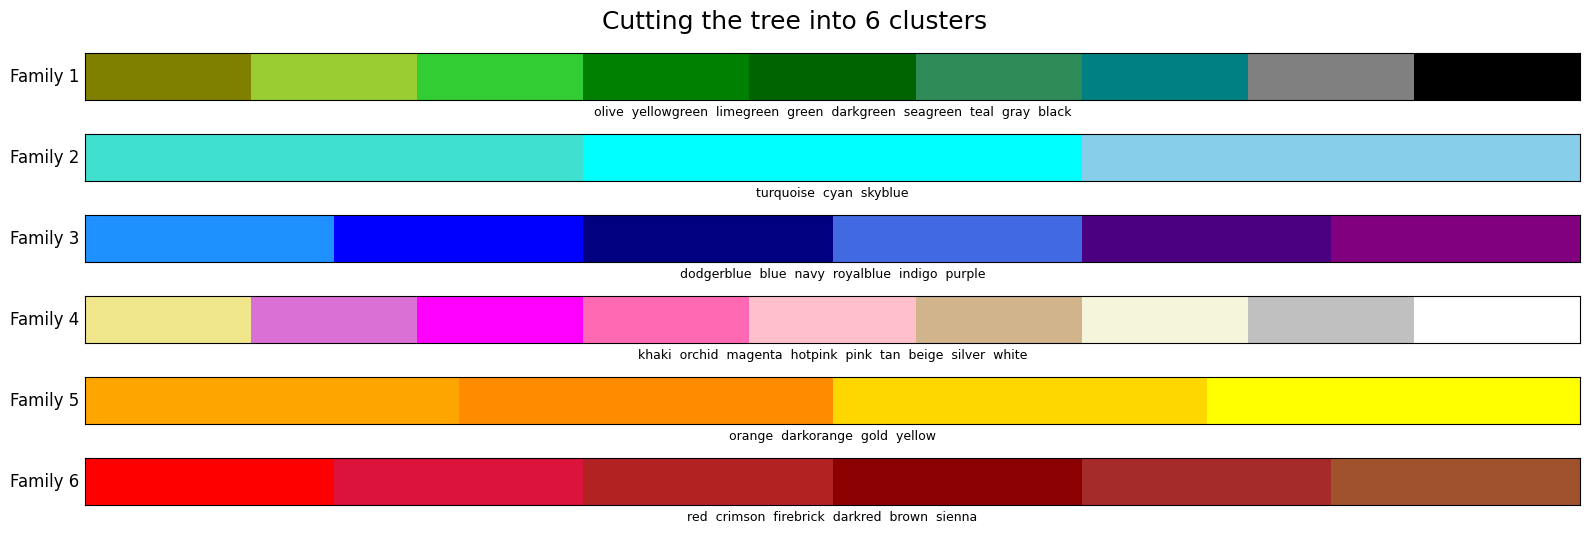

In [24]:
# Running Hierarchical Clustering and creating the dendogram

def color_tree(method='ward', k=6):
    """Draw a dendrogram of the colors, then show the k families you get by cutting the tree."""
    Z = linkage(rgb, method=method)

    # 1. The dendrogram, with each label printed on its own color
    fig, ax = plt.subplots(figsize=(16, 6))
    dendrogram(Z, labels=names, leaf_rotation=90, ax=ax, color_threshold=0, above_threshold_color='gray')
    for tick in ax.get_xticklabels():
        c = color_rgb[tick.get_text()]
        brightness = 0.299*c[0] + 0.587*c[1] + 0.114*c[2]
        tick.set_bbox(dict(facecolor=c, edgecolor='gray', pad=3))
        tick.set_color('black' if brightness > 0.5 else 'white')
    ax.set_title(f"Family tree of colors (linkage = '{method}')", size=18)
    ax.set_ylabel("Distance when merged")
    plt.show()

    # 2. Cut the tree into k clusters and show each one as a row of swatches
    families = fcluster(Z, k, criterion='maxclust')
    fig, axes = plt.subplots(k, 1, figsize=(16, 0.9*k), subplot_kw=dict(xticks=[], yticks=[]))
    for fam, ax in zip(range(1, k+1), np.atleast_1d(axes)):
        members = [i for i in range(len(names)) if families[i] == fam]
        ax.imshow([rgb[members]], aspect='auto')
        ax.set_ylabel(f"Family {fam}", rotation=0, ha='right', va='center', size=12)
        ax.set_xlabel("  ".join(names[i] for i in members), size=9)
    fig.suptitle(f"Cutting the tree into {k} clusters", size=18)
    plt.tight_layout()
    plt.show()

color_tree(method='ward', k=6)

## 🔧 Your turn: cut the tree somewhere else

1. Change `k=6` to **3**, then **10**. Where does the tree stop making sense to you? (A tall jump in the dendrogram is a hint for a good cut.)
2. Change `method='ward'` to `'single'`, then `'average'`. Linkage is how we measure the distance between *groups*. Do the families change?
3. Where does the algorithm put **maroon** and **gold**? Does that match your intuition?

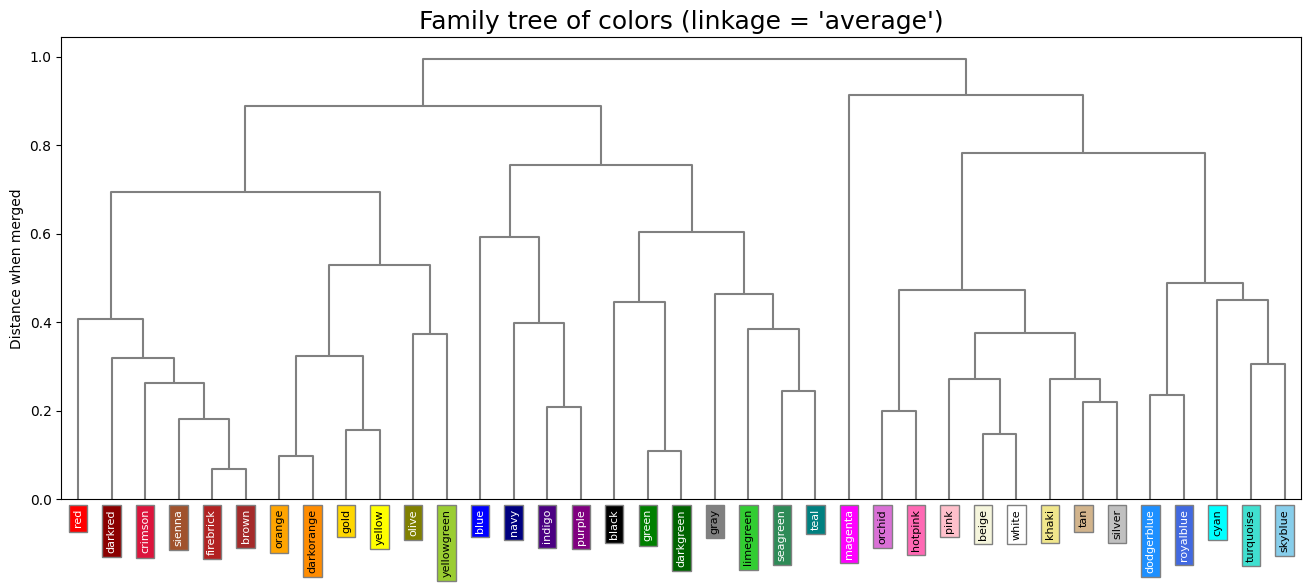

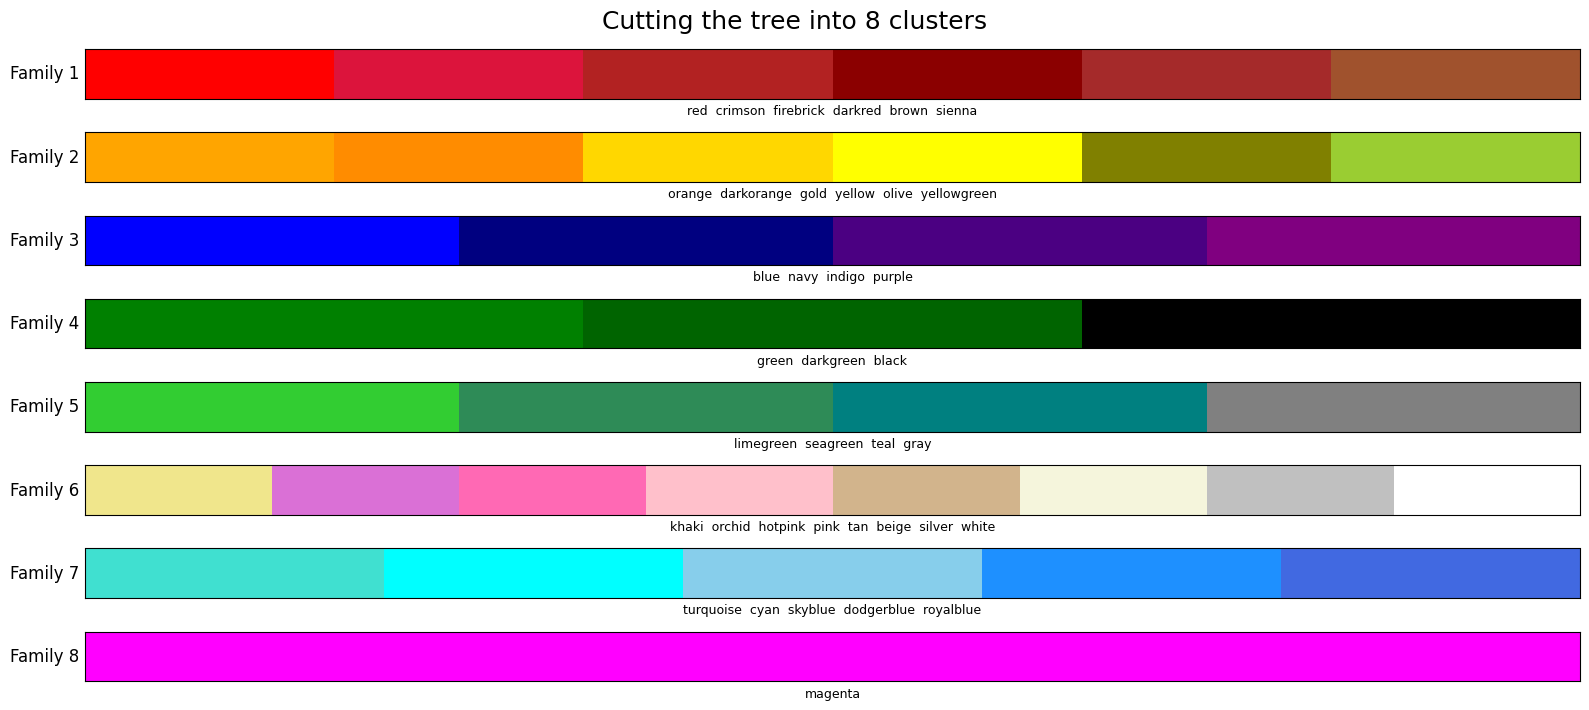

In [25]:
# Try your own settings here
color_tree(method='average', k=8)

# Congrats! You've reached the end of this tutorial!
Here are some questions to think about:

* Think of a dataset from your own field. Which of these three methods would you try first, and why?

* You saw how we took an alternative approach to understanding K-means. Can you think of some radical ways to use clustering analysis to solve a problem from your field?

##**Where to go next:**

* The [scikit-learn clustering guide](https://scikit-learn.org/stable/modules/clustering.html) and the [algorithm comparison example](https://scikit-learn.org/stable/auto_examples/cluster/plot_cluster_comparison.html) are free and beginner friendly.

##**Book Recommendations:**
[Python Data Science Handbook](https://search.lib.asu.edu/permalink/01ASU_INST/1da5cgk/cdi_nii_cinii_1970304959897478939) (2022)
* Covers K-means, Gaussian Mixture Models

[Machine Learning with PyTorch and Scikit-Learn ](https://search.lib.asu.edu/permalink/01ASU_INST/b0h8jj/alma991048892889603841) (2022)
* Covers K-means, K-means++, Hierarchical Clustering, DBSCAN
* Free to download for ASU affiliates

[Intro to Statistical Learning (Python or R)](https://www.statlearning.com) (2023)
* Covers K-means, Hierarchical Clustering
* Free to download!

[Data Clustering with Python: From Theory to Implementation](https://search.lib.asu.edu/permalink/01ASU_INST/b0h8jj/alma991049246006903841) (2025)
* Covers a breadth of clustering algorithms
* Free to download for ASU affiliates
